# Cloud droplet number from Cloudnet and from ARM NDROP

Two remote-sensing retrievals give the droplet number concentration $N_d$ used at the ground sites:

| | **Cloudnet** (`der` product, `N_scaled`) | **ARM NDROP** (`ndropmfrsr`) |
|---|---|---|
| Instruments | cloud radar ($Z$ profile) + microwave radiometer (LWP) | MFRSR (cloud optical depth $\tau$) + microwave radiometer (LWP) + ARSCL (cloud thickness $H$) |
| Cloud model | lognormal drop spectrum of fixed width, $N$ constant with height | adiabatic (or scaled sub-adiabatic) liquid water profile, $N$ constant with height |
| When | any time, liquid-only profiles without drizzle or ice | daytime, overcast, single layer |
| Result | one $N$ per profile (stored at every liquid pixel) | one $N$ per ~20 s retrieval |

This notebook writes out both retrievals, checks the equations against the actual code (CloudnetPy) and the
ARM files, shows how each responds to its input errors, and compares them on the same hours at SGP.

Run it from the repository folder (laptop or Arrhenius); it reads `data/arm/sgp/ndrop`, `data/cloudnet/arm-sgp/der`
and the built files in `results/sgp/`.

In [1]:
import glob, os
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RHO_W = 1000.0          # kg m-3
os.makedirs("figures/retrievals", exist_ok=True)
FIG = "figures/retrievals" 

## 1. Cloudnet: the scaled Frisch retrieval

**Assumptions** (Frisch et al. 1995, 2002): in each liquid pixel the droplet radii follow a lognormal distribution
with number $N$, median radius $r_0(z)$ and a *fixed* geometric width $\sigma_x$:

$$n(r)=\frac{N}{\sqrt{2\pi}\,\sigma_x r}\exp\!\left[-\frac{(\ln r-\ln r_0)^2}{2\sigma_x^2}\right],\qquad
\langle r^k\rangle = r_0^k\,e^{k^2\sigma_x^2/2}.$$

Radar reflectivity (Rayleigh, $Z=\sum D^6=64\sum r^6$) and liquid water content are then

$$Z = 64\,N\,r_0^6\,e^{18\sigma_x^2},\qquad \mathrm{LWC}=\tfrac{4\pi}{3}\rho_w N r_0^3\,e^{9\sigma_x^2/2}.$$

Eliminating $r_0$:
$$\mathrm{LWC}(z)=\frac{\pi\rho_w}{6}\,e^{-9\sigma_x^2/2}\,\sqrt{N\,Z(z)} .$$

With $N$ constant through the layer, integrating over the liquid layer and setting the result equal to the
radiometer LWP gives the **scaled** retrieval:

$$\boxed{\;N_{\rm scaled}= e^{9\sigma_x^2}\left[\frac{6\,\mathrm{LWP}}{\pi\rho_w\displaystyle\int_{\rm layer}\sqrt{Z}\,dz}\right]^{2}\;}$$

The radar fixes the *shape* of LWC(z) ($\propto\sqrt Z$), the radiometer fixes its *integral*. CloudnetPy computes it
in two steps (Frisch 2002 eqs. 5 and 6): first the scaled effective radius
$r_{e,s}=\frac{Z^{1/6}}{2\,\mathrm{LWP}^{1/3}}\left(\frac{\pi\rho_w}{6}\right)^{1/3}\left(\int\sqrt Z dz\right)^{1/3}e^{-2\sigma_x^2}$,
then $N=Z\,e^{-3\sigma_x^2}/(2r_{e,s})^6$, which is the boxed formula. CloudnetPy defaults: $\sigma_x=0.35$,
LWP uncertainty 5 g m$^{-2}$, Z uncertainty 2 dB.

**Check:** the two-step code and the closed form give the same $N$ on a synthetic profile.

In [2]:
def cloudnetpy_two_step(Z_lin, dz, lwp, sigma_x=0.35):
    # Z_lin in mm6 m-3, dz in m, lwp in kg m-2; follows cloudnetpy/products/der.py line by line
    var_x = sigma_x**2
    integral = np.sum(np.sqrt(Z_lin)) * dz
    A = Z_lin ** (1/6) / (2 * lwp ** (1/3))
    B = (np.pi * RHO_W / 6) ** (1/3)
    C_ = integral ** (1/3) * np.exp(-2 * var_x)
    der_scaled = 1.0e-3 * A * B * C_                                    # mm
    return Z_lin / ((2 * der_scaled) / np.exp(-0.5 * var_x)) ** 6       # m-3

def closed_form(Z_lin, dz, lwp, sigma_x=0.35):
    Z_si = Z_lin * 1e-18                                                # mm6 m-3 -> m6 m-3
    return np.exp(9 * sigma_x**2) * (6 * lwp / (np.pi * RHO_W * np.sum(np.sqrt(Z_si)) * dz)) ** 2

# synthetic adiabatic layer: N = 100 cm-3, LWC rising linearly to 0.4 g m-3 over 400 m, sigma_x = 0.35
z = np.arange(15, 400, 30.0); dz = 30.0; N_true = 100e6; sx = 0.35
lwc = 0.4e-3 * z / 400                                                  # kg m-3
r0 = (lwc / (4/3*np.pi*RHO_W*N_true*np.exp(4.5*sx**2))) ** (1/3)      # m
Z_lin = 64 * N_true * r0**6 * np.exp(18*sx**2) * 1e18                   # mm6 m-3
lwp = lwc.sum() * dz
print(f"LWP {lwp*1e3:.0f} g m-2, Z {10*np.log10(Z_lin.min()):.0f} to {10*np.log10(Z_lin.max()):.0f} dBZ")
print(f"true N {N_true/1e6:.1f} cm-3 | CloudnetPy two-step {cloudnetpy_two_step(Z_lin, dz, lwp, sx).mean()/1e6:.1f} | closed form {closed_form(Z_lin, dz, lwp, sx)/1e6:.1f}")

LWP 76 g m-2, Z -46 to -18 dBZ
true N 100.0 cm-3 | CloudnetPy two-step 100.0 | closed form 100.0


## 2. ARM NDROP: the adiabatic retrieval

**Assumptions:** a single liquid layer of thickness $H$ whose liquid water content increases linearly with height,
$\mathrm{LWC}(z)=c_w z$ (adiabatic: $c_w=\Gamma$, the condensation rate from cloud-base $T$ and $p$; sub-adiabatic:
$c_w=\beta\Gamma$), constant $N$, volume and effective radius related by $r_v^3=k\,r_e^3$, and extinction efficiency
$Q_{\rm ext}=2$. Then $\mathrm{LWP}=c_wH^2/2$ and

$$\tau=\int_0^H 2\pi r_e^2 N\,dz=\frac{6\pi}{5}N^{1/3}\left(\frac{3c_w}{4\pi\rho_w k}\right)^{2/3}H^{5/3}.$$

Eliminating $H$ with the LWP:

$$\boxed{\;N_{\rm ad}=K\;\Gamma^{1/2}\,\tau^{3}\,\mathrm{LWP}^{-5/2}\;}\qquad
K_{\rm textbook}=\left(\frac{5}{6\pi}\right)^{3}\left(\frac{4\pi\rho_w k}{3}\right)^{2}2^{-5/2}\approx 3.7\times10^{4}\ (k=0.8,\ \text{SI}).$$

ARM's product applies the adiabaticity $\beta=\mathrm{LWP}/\mathrm{LWP}_{\rm ad}$ with $\mathrm{LWP}_{\rm ad}=\Gamma H^2/2$
from the ARSCL cloud thickness:

$$\boxed{\;N = N_{\rm ad}\,\beta^{1/2}=\sqrt2\,K\,\frac{\tau^{3}}{\mathrm{LWP}^{2}\,H}\;}$$

in which the condensation rate cancels. This `drop_number_conc` is the NDROP value used in our builds.

**Check against the ARM files** (below): the stored adiabatic and β-corrected values follow these forms with
essentially zero scatter, and the fit gives ARM's constant $K$, which is about twice the textbook value above (a
different convention for the drop-spectrum or extinction constants; see the NDROP documentation,
doi:10.5439/1131339).

5031 retrievals; fitted exponents tau 3.000, LWP -2.500, Gamma 0.500
ARM constant K = 7.823e+04 (SI); textbook K (k=0.8) = 3.705e+04; ratio 2.11
beta-corrected N vs sqrt(2) K tau^3 / (LWP^2 H): median ratio 1.0000, 5-95% 0.7900-1.0000
median adiabaticity LWP/LWP_ad 0.52; median N 79, N_ad 106 cm-3


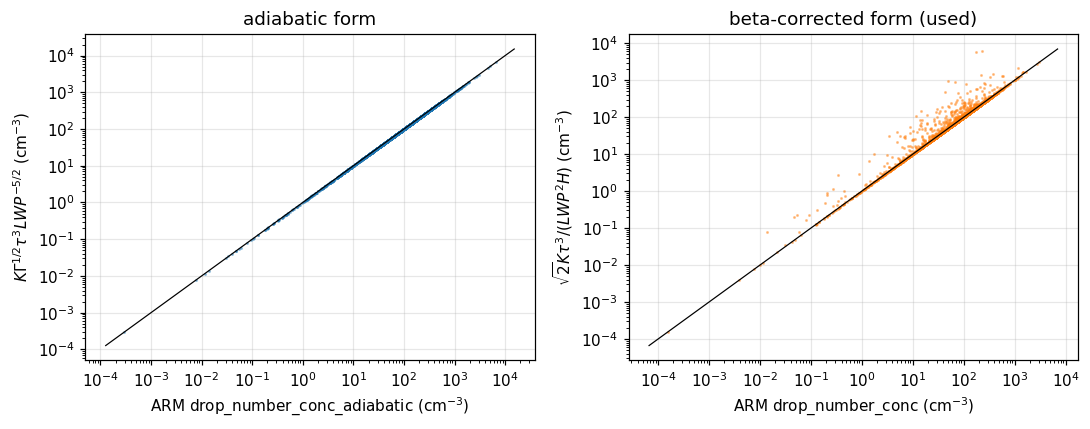

In [3]:
def ndrop_samples(folder="data/arm/sgp/ndrop", step=8, nmax=4000):
    cols = ["optical_depth_instantaneous", "lwp_meas", "condensation_rate", "drop_number_conc",
            "drop_number_conc_adiabatic", "cloud_thickness", "lwp_adiabatic"]
    rows = []
    for f in sorted(glob.glob(f"{folder}/*.nc"))[::step]:
        with xr.open_dataset(f) as d:
            v = {k: d[k].values.astype(float) for k in cols}
        m = np.all([np.isfinite(x) & (x > 0) for x in v.values()], axis=0)
        if m.any():
            rows.append(pd.DataFrame({k: v[k][m] for k in cols}))
        if sum(len(r) for r in rows) > nmax:
            break
    return pd.concat(rows, ignore_index=True).rename(columns={"optical_depth_instantaneous": "tau", "lwp_meas": "lwp",
            "condensation_rate": "G", "drop_number_conc": "N", "drop_number_conc_adiabatic": "Nad",
            "cloud_thickness": "H", "lwp_adiabatic": "lwp_ad"})

s = ndrop_samples()
X = np.column_stack([np.ones(len(s)), np.log(s.tau), np.log(s.lwp), np.log(s.G)])
b = np.linalg.lstsq(X, np.log(s.Nad), rcond=None)[0]
K = np.exp(b[0])
K_text = (5/(6*np.pi))**3 * (4*np.pi*RHO_W*0.8/3)**2 * 2**-2.5
print(f"{len(s)} retrievals; fitted exponents tau {b[1]:.3f}, LWP {b[2]:.3f}, Gamma {b[3]:.3f}")
print(f"ARM constant K = {K:.4g} (SI); textbook K (k=0.8) = {K_text:.4g}; ratio {K/K_text:.2f}")
N_formula = np.sqrt(2) * K * s.tau**3 / (s.lwp**2 * s.H)
print(f"beta-corrected N vs sqrt(2) K tau^3 / (LWP^2 H): median ratio {np.median(s.N/N_formula):.4f}, "
      f"5-95% {np.percentile(s.N/N_formula, 5):.4f}-{np.percentile(s.N/N_formula, 95):.4f}")
print(f"median adiabaticity LWP/LWP_ad {np.median(s.lwp/s.lwp_ad):.2f}; median N {s.N.median()/1e6:.0f}, N_ad {s.Nad.median()/1e6:.0f} cm-3")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].loglog(s.Nad/1e6, K*np.sqrt(s.G)*s.tau**3*s.lwp**-2.5/1e6, ".", ms=2, alpha=0.4)
ax[0].set(xlabel="ARM drop_number_conc_adiabatic (cm$^{-3}$)", ylabel=r"$K\Gamma^{1/2}\tau^3 LWP^{-5/2}$ (cm$^{-3}$)", title="adiabatic form")
ax[1].loglog(s.N/1e6, N_formula/1e6, ".", ms=2, alpha=0.4, color="C1")
ax[1].set(xlabel="ARM drop_number_conc (cm$^{-3}$)", ylabel=r"$\sqrt{2}K\tau^3/(LWP^2H)$ (cm$^{-3}$)", title="beta-corrected form (used)")
for a in ax: lim = a.get_xlim(); a.plot(lim, lim, "k-", lw=0.8)
fig.tight_layout(); fig.savefig(f"{FIG}/ndrop_equation_check.png", dpi=150)

## 3. How each retrieval responds to its input errors

Log-derivatives of the two boxed equations:

| input | Cloudnet $N_{\rm scaled}$ | NDROP $N$ (used) |
|---|---|---|
| LWP | $\partial\ln N/\partial\ln\mathrm{LWP}=+2$ | $-2$ |
| radar calibration offset $\Delta$ (dB) | $N\times10^{-\Delta/10}$ (1 dB → −21 %) | – |
| optical depth $\tau$ | – | $+3$ |
| cloud thickness $H$ | (through the $Z$ integral only) | $-1$ |
| assumed width $\sigma_x$ | $N\propto e^{9\sigma_x^2}$ | – |
| drizzle drops in the radar volume | $Z$ too high → $N$ **too low** | small (τ, LWP barely change) |

LWP enters with opposite signs: a radiometer offset biases the two retrievals in opposite directions, so it shows
up strongly in their ratio. The spectral width is a pure assumption in Cloudnet: if the true $\sigma_x$ is 0.25
instead of the default 0.35, $N$ is overestimated by $e^{9(0.35^2-0.25^2)}=1.7$.

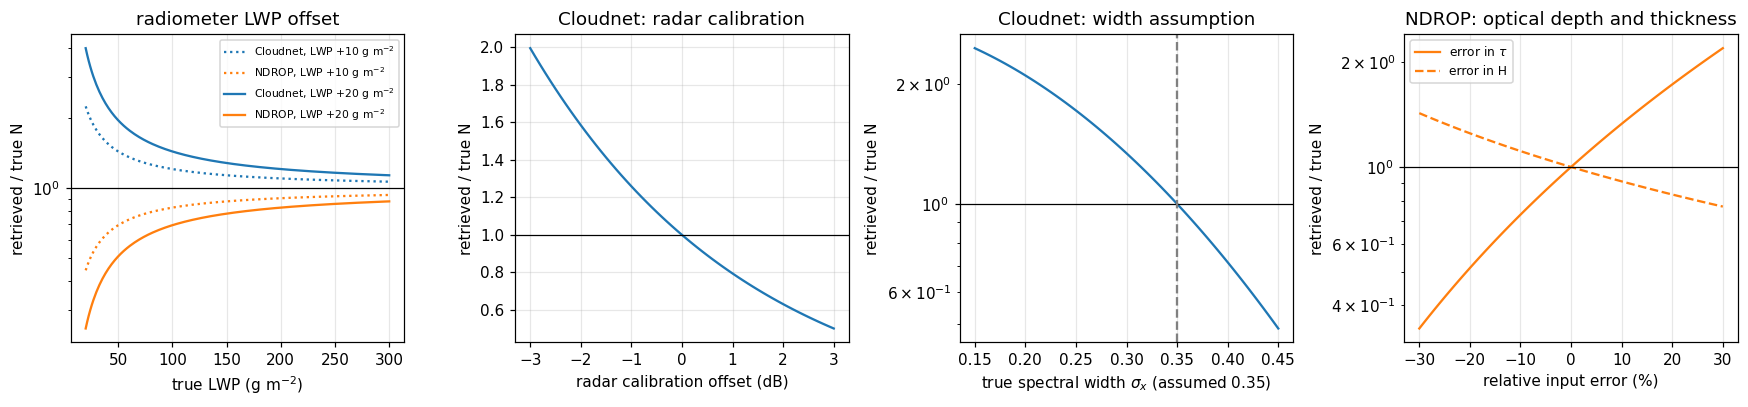

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
lwp = np.linspace(20, 300, 200)                      # g m-2
for d, ls in [(10, ":"), (20, "-")]:
    ax[0].plot(lwp, ((lwp + d)/lwp)**2, "C0"+ls, label=f"Cloudnet, LWP +{d} g m$^{{-2}}$")
    ax[0].plot(lwp, ((lwp + d)/lwp)**-2, "C1"+ls, label=f"NDROP, LWP +{d} g m$^{{-2}}$")
ax[0].axhline(1, color="k", lw=0.8); ax[0].set(xlabel="true LWP (g m$^{-2}$)", ylabel="retrieved / true N", title="radiometer LWP offset", yscale="log")
ax[0].legend(fontsize=7)
dB = np.linspace(-3, 3, 61)
ax[1].plot(dB, 10**(-dB/10), "C0"); ax[1].axhline(1, color="k", lw=0.8)
ax[1].set(xlabel="radar calibration offset (dB)", ylabel="retrieved / true N", title="Cloudnet: radar calibration")
sx = np.linspace(0.15, 0.45, 61)
ax[2].plot(sx, np.exp(9*(0.35**2 - sx**2)), "C0"); ax[2].axhline(1, color="k", lw=0.8); ax[2].axvline(0.35, color="0.5", ls="--")
ax[2].set(xlabel=r"true spectral width $\sigma_x$ (assumed 0.35)", ylabel="retrieved / true N", title="Cloudnet: width assumption", yscale="log")
e = np.linspace(-0.3, 0.3, 61)
ax[3].plot(100*e, (1+e)**3, "C1", label=r"error in $\tau$")
ax[3].plot(100*e, (1+e)**-1, "C1--", label="error in H")
ax[3].axhline(1, color="k", lw=0.8); ax[3].set(xlabel="relative input error (%)", ylabel="retrieved / true N", title="NDROP: optical depth and thickness", yscale="log")
ax[3].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/retrieval_sensitivities.png", dpi=150)

## 4. The two retrievals on the same hours at SGP

The built hourly files: `results/sgp/sgp_cloudnet.nc` (Cloudnet + SMPS) and `results/sgp/sgp_2016_2025_smps.nc`
(NDROP + SMPS), joined on the hour, both with cloud_frac ≥ 0.5. Check the printed statistics (`hourly mean` or
`hourly median`): use the same for both.

Cloudnet: hourly median Cloudnet N_scaled (scaled Frisch)
NDROP:    hourly mean retrieved Nd (NDROP)
203 matched hours on 95 days; Cloudnet/NDROP median 1.79 (IQR 1.06-3.12); r(log) 0.34


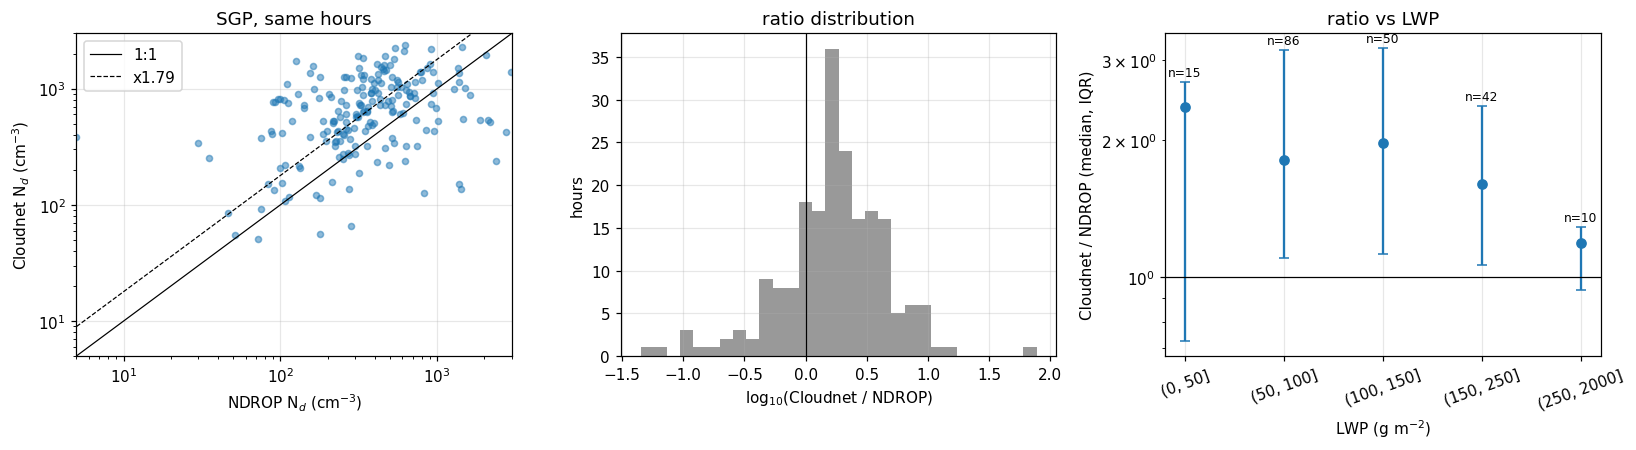

In [5]:
cn = xr.open_dataset("results/sgp/sgp_cloudnet.nc").load()
nd = xr.open_dataset("results/sgp/sgp_2016_2025_smps.nc").load()
print("Cloudnet:", cn.CDNC.attrs.get("long_name")); print("NDROP:   ", nd.CDNC.attrs.get("long_name"))
a = cn[["CDNC", "cloud_frac", "lwp_meas", "cloud_base_height", "cloud_top_height"]].to_dataframe().add_prefix("cn_")
b = nd[["CDNC", "cloud_frac", "lwp_meas", "cloud_thickness", "optical_depth_instantaneous"]].to_dataframe().add_prefix("nd_")
m = a.join(b, how="inner")
m = m[(m.cn_cloud_frac >= 0.5) & (m.nd_cloud_frac >= 0.5) & (m.cn_CDNC > 0) & (m.nd_CDNC > 0)].copy()
m["ratio"] = m.cn_CDNC / m.nd_CDNC
lw = m.cn_lwp_meas.where(m.cn_lwp_meas > 0, m.nd_lwp_meas)
m["lwp_gm2"] = lw * (1000 if np.nanmedian(lw) < 5 else 1)            # kg m-2 -> g m-2 if needed
print(f"{len(m)} matched hours on {m.index.normalize().nunique()} days; Cloudnet/NDROP median {m.ratio.median():.2f} "
      f"(IQR {m.ratio.quantile(.25):.2f}-{m.ratio.quantile(.75):.2f}); r(log) {np.corrcoef(np.log(m.cn_CDNC), np.log(m.nd_CDNC))[0,1]:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].loglog(m.nd_CDNC, m.cn_CDNC, "o", ms=4, alpha=0.5)
lim = [5, 3000]; ax[0].plot(lim, lim, "k-", lw=0.8, label="1:1")
ax[0].plot(lim, np.array(lim)*m.ratio.median(), "k--", lw=0.8, label=f"x{m.ratio.median():.2f}")
ax[0].set(xlim=lim, ylim=lim, xlabel="NDROP N$_d$ (cm$^{-3}$)", ylabel="Cloudnet N$_d$ (cm$^{-3}$)", title="SGP, same hours"); ax[0].legend()
ax[1].hist(np.log10(m.ratio), bins=30, color="0.6"); ax[1].axvline(0, color="k", lw=0.8)
ax[1].set(xlabel="log$_{10}$(Cloudnet / NDROP)", ylabel="hours", title="ratio distribution")
bins = [0, 50, 100, 150, 250, 2000]
g = m.groupby(pd.cut(m.lwp_gm2, bins), observed=True).ratio
ax[2].errorbar(range(len(g)), g.median(), yerr=[g.median()-g.quantile(.25), g.quantile(.75)-g.median()], fmt="o", capsize=3)
ax[2].set_xticks(range(len(g))); ax[2].set_xticklabels([str(i) for i in g.median().index], rotation=20)
ax[2].axhline(1, color="k", lw=0.8); ax[2].set(xlabel="LWP (g m$^{-2}$)", ylabel="Cloudnet / NDROP (median, IQR)", title="ratio vs LWP", yscale="log")
for i, n in enumerate(g.size()): ax[2].annotate(f"n={n}", (i, g.quantile(.75).iloc[i]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/sgp_cloudnet_vs_ndrop.png", dpi=150)

The opposite LWP exponents predict the ratio's LWP dependence if the radiometer LWP is biased: Cloudnet/NDROP
$\propto \mathrm{LWP}^{4}$ for a given error, strongest in thin clouds. A ratio that stays roughly constant across LWP
bins points instead to a multiplicative bias such as radar calibration or the assumed spectral width.

## 5. One day at SGP: Cloudnet profile and NDROP time series

example day: 2024-04-18


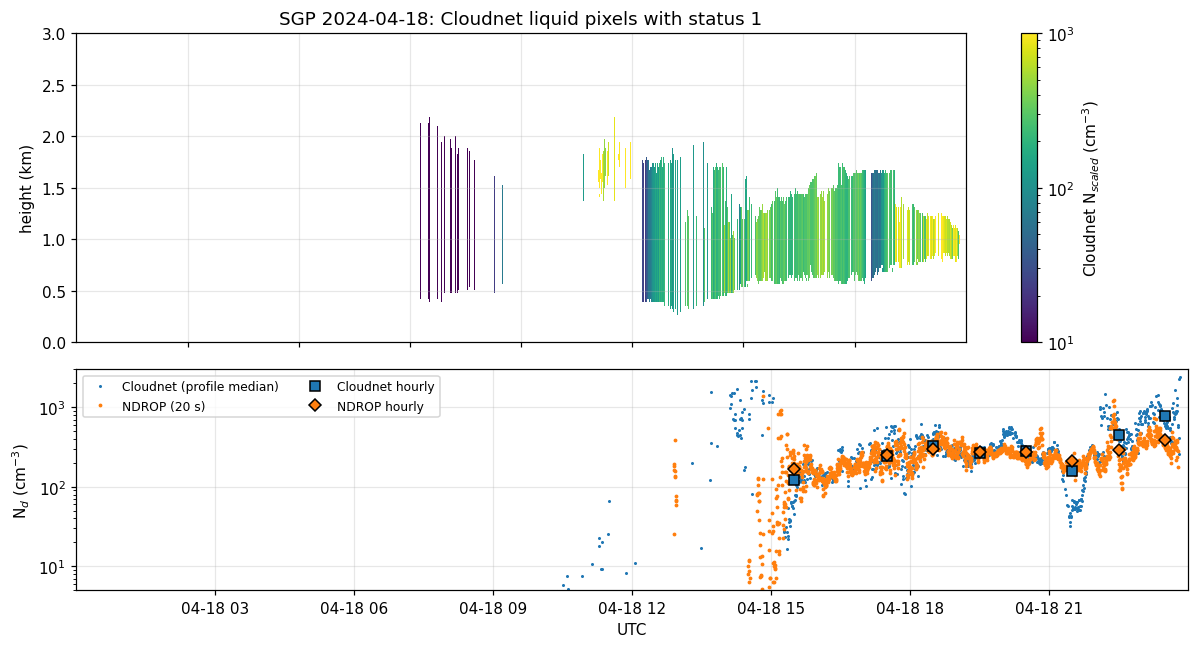

In [6]:
days = m.index.normalize().value_counts()
day = None
for d in days.index:
    ds = d.strftime("%Y%m%d")
    if glob.glob(f"data/cloudnet/arm-sgp/der/{ds}_*der*.nc") and glob.glob(f"data/arm/sgp/ndrop/*{ds}*.nc"):
        day = d; break
print("example day:", day.date() if day is not None else "none with both raw files")
if day is not None:
    ds = day.strftime("%Y%m%d")
    der = xr.open_dataset(glob.glob(f"data/cloudnet/arm-sgp/der/{ds}_*der*.nc")[0])
    Nsc = der.N_scaled.where(der.der_retrieval_status == 1) / 1e6
    hagl = der.height - float(np.nanmean(der.altitude))
    ndr = xr.open_dataset(glob.glob(f"data/arm/sgp/ndrop/*{ds}*.nc")[0])
    t_nd = pd.to_datetime(ndr.time.values); Nnd = ndr.drop_number_conc.values / 1e6
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
    pc = ax[0].pcolormesh(der.time, hagl/1000, Nsc.T, cmap="viridis", norm=plt.matplotlib.colors.LogNorm(10, 1000), shading="auto")
    fig.colorbar(pc, ax=ax[0], label="Cloudnet N$_{scaled}$ (cm$^{-3}$)")
    ax[0].set(ylim=(0, 3), ylabel="height (km)", title=f"SGP {day.date()}: Cloudnet liquid pixels with status 1")
    prof = Nsc.median("height")
    ax[1].semilogy(der.time, prof, ".", ms=2, label="Cloudnet (profile median)")
    ax[1].semilogy(t_nd, Nnd, ".", ms=3, label="NDROP (20 s)", color="C1")
    hh = m[m.index.normalize() == day]
    ax[1].semilogy(hh.index + pd.Timedelta("30min"), hh.cn_CDNC, "s", color="C0", mec="k", label="Cloudnet hourly")
    ax[1].semilogy(hh.index + pd.Timedelta("30min"), hh.nd_CDNC, "D", color="C1", mec="k", label="NDROP hourly")
    ax[1].set(ylim=(5, 3000), ylabel="N$_d$ (cm$^{-3}$)", xlabel="UTC"); ax[1].legend(fontsize=8, ncol=2)
    fig.tight_layout(); fig.savefig(f"{FIG}/sgp_example_day.png", dpi=150)

## 6. Summary

* **Cloudnet:** $N=e^{9\sigma_x^2}\,[6\,\mathrm{LWP}/(\pi\rho_w\int\sqrt Z\,dz)]^2$. It scales with LWP$^2$, inversely with
  radar reflectivity (1 dB ≈ 21–26 %), and with an assumed spectral width that alone can change $N$ by a factor
  of ~1.7. Drizzle biases it low.
* **NDROP:** $N=\sqrt2\,K\,\tau^3/(\mathrm{LWP}^2H)$ (adiabatic form $K\Gamma^{1/2}\tau^3\mathrm{LWP}^{-5/2}$). It scales
  with the cube of optical depth and inversely with LWP$^2$ and cloud thickness; daytime overcast only.
* The two depend on LWP with **opposite signs**, so the Cloudnet/NDROP ratio is a sensitive test of radiometer
  errors, while a constant ratio points to radar calibration or the width assumption.
* Constant multiplicative biases leave the susceptibility $S$ (a log-log slope) unchanged but shift the closure
  diameter $D_\Delta$, which is why Cloudnet sites are used for $S$ until their absolute $N_d$ is checked against
  in-situ data.

References: Frisch et al. (1995) J. Atmos. Sci. 52, 2788; Frisch et al. (2002) J. Atmos. Oceanic Technol. 19, 835;
CloudnetPy `products/der.py`; ARM NDROP-MFRSR VAP, doi:10.5439/1131339.